# ラベルを付ける文書を賢く選んで、少ないラベルで精度を上げる（能動学習）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/12_classification/active_learning.ipynb)

NLP クックブック 12-18 ／ テキスト分類

アノテーションの予算が限られているので、ランダムに選ぶより「モデルが迷っている文書」から優先してラベルを付け、少ない件数で精度を上げたい。livedoor ニュースコーパスの記事タイトルで、ラベルを少しずつ増やすシミュレーションをして確かめる。

In [1]:
import io, tarfile, urllib.request
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

def load_livedoor():
    """livedoor ニュースコーパス (株式会社ロンウイット配布、記事は CC BY-ND 2.1 JP) を DataFrame にする"""
    url = "https://www.rondhuit.com/download/ldcc-20140209.tar.gz"
    with urllib.request.urlopen(url) as r:
        tar = tarfile.open(fileobj=io.BytesIO(r.read()), mode="r:gz")
    rows = []
    for m in tar.getmembers():
        parts = m.name.split("/")
        if m.isfile() and len(parts) == 3 and parts[2] != "LICENSE.txt":
            lines = tar.extractfile(m).read().decode("utf-8").split("\n")
            rows.append({"label": parts[1], "title": lines[2], "text": "\n".join(lines[3:])})
    return pd.DataFrame(rows)

df = load_livedoor().sample(4000, random_state=0).reset_index(drop=True)   # CPU で回せるよう 4000 件に減らす
y = df["label"].to_numpy()
pool_idx, test_idx = train_test_split(np.arange(len(df)), test_size=1000, stratify=y, random_state=0)
print("プール (ラベルを付ける候補):", len(pool_idx), " テスト:", len(test_idx))

# 特徴量は 2 種類。ラベルを使わないので、最初に一度だけ作っておけばよい
tfidf = TfidfVectorizer(analyzer="char", ngram_range=(1, 3), sublinear_tf=True, min_df=2)   # 1 回しか出ない n-gram は捨てて軽くする
X_tfidf = tfidf.fit(df["title"].iloc[pool_idx]).transform(df["title"])   # 語彙と IDF はプールだけから作る
model = SentenceTransformer("intfloat/multilingual-e5-small", device="cpu")   # MIT ライセンス
# ダウンロードとモデルの読み込みを含めて、2 コアで 2〜4 分
X_emb = model.encode(["query: " + t for t in df["title"]], normalize_embeddings=True, batch_size=64, show_progress_bar=False)
print(X_tfidf.shape, X_emb.shape)

プール (ラベルを付ける候補): 3000  テスト: 1000
(4000, 25345) (4000, 384)


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

def make_clf():
    # 何百回も学習し直すので、速い liblinear (クラスごとの 2 値分類 = one-vs-rest) を使う
    return OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"))

def uncertainty(proba, strategy):
    """値が大きいほど「モデルが迷っている」"""
    p = np.sort(proba, axis=1)[:, ::-1]
    if strategy == "least_confident":
        return 1 - p[:, 0]                                  # 最大の確率が低い
    if strategy == "margin":
        return -(p[:, 0] - p[:, 1])                         # 1 位と 2 位の確率の差が小さい
    if strategy == "entropy":
        return -(proba * np.log(proba + 1e-12)).sum(axis=1) # 確率の分布が平ら

def simulate(X, strategy, seed, init=None, n_init=20, batch=40, budget=420):
    """ラベル付きを n_init 件から batch 件ずつ増やし、各段階のテスト正解率を返す。
    ラベルは本当は人が付けるが、ここでは正解を隠しておいて、選ばれたものだけ見せる"""
    rng = np.random.default_rng(seed)
    labeled = list(rng.choice(pool_idx, n_init, replace=False) if init is None else init)
    accs = []
    while True:
        clf = make_clf().fit(X[labeled], y[labeled])
        accs.append(clf.score(X[test_idx], y[test_idx]))
        if len(labeled) >= budget:
            return np.array(accs), labeled
        rest = np.setdiff1d(pool_idx, labeled)
        if strategy == "random":
            new = rng.choice(rest, batch, replace=False)
        else:
            new = rest[np.argsort(-uncertainty(clf.predict_proba(X[rest]), strategy))[:batch]]
        labeled += list(new)

strategies = ["random", "least_confident", "margin", "entropy"]
seeds = range(10)
sizes = np.arange(20, 421, 40)   # 20, 60, ..., 420 件
at = {n: i for i, n in enumerate(sizes)}
# 2 特徴量 × 4 方法 × 10 種で、分類器を 880 回学習し直す。2 コアで 1〜4 分 (Colab でも数分以内)
res = {(f, s): np.array([simulate(X, s, seed)[0] for seed in seeds])
       for f, X in [("emb", X_emb), ("tfidf", X_tfidf)] for s in strategies}

for f, X in [("emb", X_emb), ("tfidf", X_tfidf)]:
    full = make_clf().fit(X[pool_idx], y[pool_idx]).score(X[test_idx], y[test_idx])
    print(f"[{f}] プール全件 ({len(pool_idx)} 件) で学習したときの正解率: {full:.3f}")
    print(pd.DataFrame({s: [f"{res[f, s][:, i].mean():.3f} ± {res[f, s][:, i].std():.3f}" for i in [at[20], at[100], at[220], at[420]]]
                        for s in strategies}, index=[f"{n} 件" for n in [20, 100, 220, 420]]).to_string(), "\n")

[emb] プール全件 (3000 件) で学習したときの正解率: 0.813
              random least_confident         margin        entropy
20 件   0.306 ± 0.065   0.306 ± 0.065  0.306 ± 0.065  0.306 ± 0.065
100 件  0.567 ± 0.031   0.435 ± 0.054  0.585 ± 0.033  0.388 ± 0.063
220 件  0.684 ± 0.021   0.650 ± 0.045  0.707 ± 0.010  0.602 ± 0.031
420 件  0.732 ± 0.014   0.717 ± 0.028  0.754 ± 0.009  0.695 ± 0.022 

[tfidf] プール全件 (3000 件) で学習したときの正解率: 0.838
              random least_confident         margin        entropy
20 件   0.247 ± 0.060   0.247 ± 0.060  0.247 ± 0.060  0.247 ± 0.060
100 件  0.497 ± 0.045   0.359 ± 0.046  0.465 ± 0.079  0.368 ± 0.085
220 件  0.638 ± 0.025   0.614 ± 0.033  0.656 ± 0.033  0.600 ± 0.037
420 件  0.714 ± 0.013   0.723 ± 0.014  0.740 ± 0.010  0.711 ± 0.017 



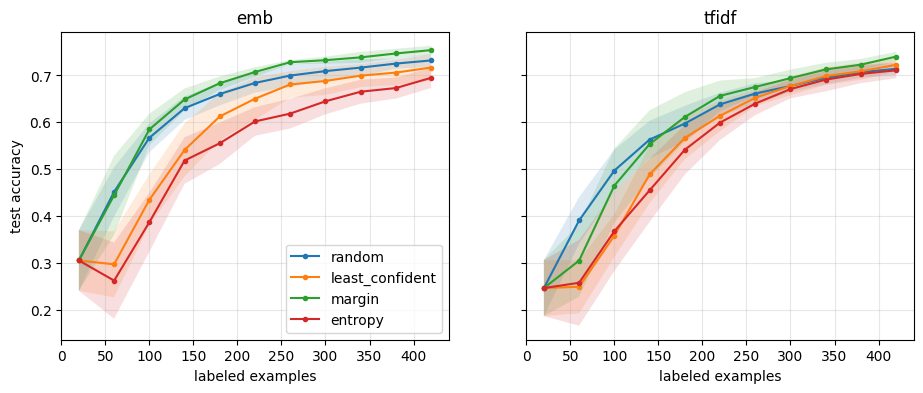

[emb] least_confident 100件: -0.132±0.069 (0/10 勝)  220件: -0.034±0.052 (4/10 勝)  420件: -0.015±0.036 (4/10 勝)
[emb] margin          100件: +0.018±0.043 (5/10 勝)  220件: +0.023±0.028 (8/10 勝)  420件: +0.022±0.017 (9/10 勝)
[emb] entropy         100件: -0.180±0.079 (0/10 勝)  220件: -0.082±0.034 (0/10 勝)  420件: -0.037±0.025 (1/10 勝)
[tfidf] least_confident 100件: -0.139±0.071 (0/10 勝)  220件: -0.024±0.033 (2/10 勝)  420件: +0.009±0.013 (6/10 勝)
[tfidf] margin          100件: -0.032±0.104 (5/10 勝)  220件: +0.018±0.043 (7/10 勝)  420件: +0.026±0.015 (10/10 勝)
[tfidf] entropy         100件: -0.129±0.081 (0/10 勝)  220件: -0.039±0.032 (1/10 勝)  420件: -0.003±0.017 (5/10 勝)


In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, f in zip(axes, ["emb", "tfidf"]):
    for s in strategies:
        m, sd = res[f, s].mean(axis=0), res[f, s].std(axis=0)
        ax.plot(sizes, m, "o-", ms=3, label=s)
        ax.fill_between(sizes, m - sd, m + sd, alpha=0.15)
    ax.set_title(f); ax.set_xlabel("labeled examples"); ax.grid(alpha=0.3)
axes[0].set_ylabel("test accuracy"); axes[0].legend(); plt.show()

# 同じ種 (= 同じ最初の 20 件) どうしで、ランダムとの差を取る
for f in ["emb", "tfidf"]:
    for s in strategies[1:]:
        d = res[f, s] - res[f, "random"]
        print(f"[{f}] {s:15}", "  ".join(f"{n}件: {d[:, i].mean():+.3f}±{d[:, i].std():.3f} ({(d[:, i] > 0).sum()}/10 勝)"
                                          for i, n in [(at[100], 100), (at[220], 220), (at[420], 420)]))

In [4]:
from sklearn.neighbors import NearestNeighbors

# どんな文書が選ばれたか: 種 0 で 420 件まで選んだ集合を比べる
nn = NearestNeighbors(n_neighbors=11, metric="cosine").fit(X_emb[pool_idx])
def typicality(idx):
    """近い 10 件との平均コサイン類似度。低いほど周りに似た文書がない (外れ値寄り)"""
    dist, _ = nn.kneighbors(X_emb[idx])
    return 1 - dist[:, 1:].mean(axis=1)

rows = {}
for s in strategies:
    _, chosen = simulate(X_emb, s, seed=0)
    chosen = np.array(chosen[20:])   # 最初のランダムな 20 件を除いた、方法が選んだ 400 件
    cnt = pd.Series(y[chosen]).value_counts()
    rows[s] = {"典型度 (平均)": typicality(chosen).mean(), "タイトルの長さ": df["title"].iloc[chosen].str.len().mean(),
               "最多クラスの件数": f"{cnt.iloc[0]} ({cnt.index[0]})", "最少クラスの件数": f"{cnt.iloc[-1]} ({cnt.index[-1]})"}
rows["(プール全体)"] = {"典型度 (平均)": typicality(pool_idx).mean(), "タイトルの長さ": df["title"].iloc[pool_idx].str.len().mean()}
display(pd.DataFrame(rows).T.round(3))

_, chosen = simulate(X_emb, "entropy", seed=0, budget=60)
print("エントロピーで最初に選ばれた 40 件 (の一部):")
for i in chosen[20:30]:
    print(f"  [{y[i]}] {df['title'][i]}")

,典型度 (平均),タイトルの長さ,最多クラスの件数,最少クラスの件数
random,0.878718,36.46,63 (movie-enter),30 (livedoor-homme)
least_confident,0.87255,35.47,56 (it-life-hack),23 (smax)
margin,0.875402,36.3675,61 (it-life-hack),34 (livedoor-homme)
entropy,0.873063,34.34,59 (it-life-hack),15 (smax)
(プール全体),0.879373,37.587,NaN,NaN


エントロピーで最初に選ばれた 40 件 (の一部):
  [topic-news] 日本の引きこもりに海外から相次ぐ心配の声
  [movie-enter] ピラミッドが20年でつくられたという話は嘘
  [dokujo-tsushin] ブーケトスは人権侵害なのか！？
  [topic-news] 「いつまでも売れると思ってんの」 人々のCD離れが深刻に
  [dokujo-tsushin] 昔、不幸の手紙は今やチェーンメール
  [topic-news] 慶應大学だけ書籍の売れ筋が「おかしい」と話題に
  [livedoor-homme] 急成長を遂げるFacebookに忍び寄る影
  [topic-news] オダギリジョーの“こうだくみ”サインが韓国で物議
  [topic-news] 岩波書店の採用方法がネットで物議 厚労相も反応
  [livedoor-homme] 「今の会社は刺激が足りません」 - 辛口説教部屋 vol.46


In [5]:
from sklearn.cluster import KMeans

# コールドスタート: 最初の 20 件をランダムに選ぶか、クラスタリングで代表的な文書を選ぶか
def kmeans_init(seed, k=20):
    km = KMeans(n_clusters=k, n_init=3, random_state=seed).fit(X_emb[pool_idx])
    return [pool_idx[np.argmin(((X_emb[pool_idx] - c) ** 2).sum(axis=1))] for c in km.cluster_centers_]   # 重心に最も近い文書

for name, make in [("random", lambda seed: np.random.default_rng(seed).choice(pool_idx, 20, replace=False)), ("k-means", kmeans_init)]:
    accs, ncls = [], []
    for seed in seeds:
        init = make(seed)
        ncls.append(len(set(y[init])))
        accs.append(simulate(X_emb, "entropy", seed, init=init, budget=100)[0])
    accs = np.array(accs)
    print(f"最初の 20 件 = {name:8}: 含まれるクラス数 {np.mean(ncls):.1f}/9   正解率 20 件 {accs[:, 0].mean():.3f}±{accs[:, 0].std():.3f}"
          f"   (その後エントロピーで) 100 件 {accs[:, -1].mean():.3f}±{accs[:, -1].std():.3f}")

最初の 20 件 = random  : 含まれるクラス数 7.9/9   正解率 20 件 0.306±0.065   (その後エントロピーで) 100 件 0.388±0.063
最初の 20 件 = k-means : 含まれるクラス数 8.8/9   正解率 20 件 0.319±0.039   (その後エントロピーで) 100 件 0.398±0.063


- 能動学習 (active learning) は、モデルに「次にラベルを付けると役立ちそうな文書」を選ばせ、人がそれにラベルを付けてモデルを学習し直す、を繰り返す。ここでは正解ラベルを隠しておき、選ばれた文書のラベルだけを使うことで、人の作業をシミュレーションしている。データと特徴量は、この章の「文埋め込みを特徴量にして少ない学習データで分類する」と同じ構成にした。livedoor ニュースコーパスは CC BY-ND 2.1 JP（改変禁止）、`intfloat/multilingual-e5-small` は MIT ライセンス。
- 不確実性サンプリングは Lewis と Gale (1994, SIGIR) がテキスト分類で提案した。確信度・マージン・エントロピーなどの選び方の整理は Settles のサーベイ (2009) にある。
- 種 10 個の平均で、マージン（1 位と 2 位の確率の差）で選ぶ方法は 420 件の時点でランダムより正解率が高く、同じ種どうしの差は埋め込みで +0.022 ± 0.017（10 種中 9 勝）、TF-IDF で +0.026 ± 0.015（10 勝）だった。100 件の時点では勝ち負けが半々で、差は種によるばらつきに埋もれている。ラベルが少ないうちはモデルの確率が当てにならないためと考えられる。
- 確信度の低さ (least confident) やエントロピーで選ぶと、序盤はランダムより悪かった（100 件で、埋め込みのエントロピーは -0.180、TF-IDF でも -0.129、どちらも 10 種すべてで負け）。9 クラスでは、どのクラスにも当てはまりそうな曖昧な文書ほど確率が平らになり、優先して選ばれやすいためと考えられる。マージンは上位 2 クラスの差だけを見るので、この影響を受けにくいと考えられる。
- 選ばれたラベル付きデータは母集団の縮図ではない。種 0 の 1 回だけの比較だが、エントロピーで選んだ 400 件では smax が 15 件しかなかった（ランダムでは最少のクラスでも 30 件）。確信度やエントロピーで選んだ集合はタイトルもやや短い（プール平均 37.6 文字に対し 34〜35 文字）。この集合で精度を測ると偏るので、評価用のデータは必ず別にランダムに取っておく。また、能動学習で集めたデータが別のモデルの学習でもランダムより良いとは限らないことを Lowell ら (2019, EMNLP) が報告している。
- 最初のモデルがないとき（コールドスタート）は、不確実性を計算できないので最初の数十件は別の方法で選ぶ。k-means の各クラスタの代表を選ぶと、最初の 20 件に含まれるクラス数は平均 7.9 から 8.8 に増えた。ただし正解率の差（20 件で 0.319 と 0.306）は種によるばらつきの範囲内だった。
- ランダムに選んだときの曲線は、この章の「学習データを増やすと精度がどう変わるか調べる（学習曲線）」と同じ考え方の曲線である。能動学習はこの曲線を左に（少ない件数側に）ずらす工夫だが、ここではプール全件（3000 件）で学習した正解率（埋め込み 0.813、TF-IDF 0.838）には 420 件ではまだ届かない。ラベルを付ける代わりにルールでまとめてラベルを付ける方法は、この章の「ルールでラベルを付けて分類器を学習する（弱教師あり学習、Snorkel）」を参照。